# Choosing settings and clustering curves

The guide checks whether the gene ranking depends on the model settings, and groups genes by the shape of their curves. Run the settings check when the ranking matters for a decision. On the example data, the defaults (`n_bsplines=10`, `n_bins=50`) keep most of the top genes of the richest setting but reorder the rest. It uses the Legnini et al. organoids with the organoid as the replicate; [Comparing conditions with replicates](replicates_tutorial.ipynb) explains the tests and the caveats of this anchor.

In [1]:
# One BLAS thread per process; set before numpy is imported.
import os

for var in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMEXPR_NUM_THREADS"):
    os.environ[var] = "1"

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

import diffsvg as dvg

plt.rcParams["figure.dpi"] = 80
N_WORKERS = int(os.environ.get("DIFFSVG_WORKERS", 4))
LAYER = "log1p_norm"

## Data and anchor

The setup is the same as in [diffsvg in 10 minutes](quickstart.ipynb). The maps show the distance to the anchor in one control and one SHH section.

In [2]:
adata = dvg.datasets.legnini23()

shh = sc.get.obs_df(adata, "SHH")["SHH"].to_numpy()
adata.obs["SHH+"] = (shh > np.percentile(shh, 99)).astype(str)

sq.tl.var_by_distance(
    adata, cluster_key="SHH+", groups="True", library_key="sample", covariates=["condition", "organoid"]
)
design = adata.obsm["design_matrix"]
design["organoid"] = design["organoid"].astype(str)

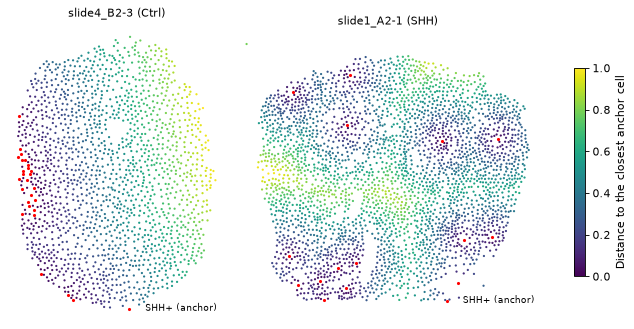

In [3]:
EXAMPLE_SLIDES = ["slide4_B2-3", "slide1_A2-1"]

fig, axes = plt.subplots(1, 2, figsize=(9, 4), constrained_layout=True)
for ax, slide in zip(axes, EXAMPLE_SLIDES, strict=True):
    in_slide = (design["sample"] == slide).to_numpy()
    anchor = in_slide & design["True"].isna().to_numpy()
    others = in_slide & ~anchor
    xy = adata.obsm["spatial"]
    points = ax.scatter(
        *xy[others].T, c=design["True"].to_numpy()[others], cmap="viridis", vmin=0, vmax=1, s=4, linewidth=0
    )
    ax.scatter(*xy[anchor].T, color="red", s=8, linewidth=0, label="SHH+ (anchor)")
    ax.set_title(f"{slide} ({design.loc[in_slide, 'condition'].iloc[0]})", fontsize=10)
    ax.set_aspect("equal")
    ax.set_axis_off()
    ax.legend(frameon=False, fontsize=8, loc="lower right")
fig.colorbar(points, ax=axes, shrink=0.7, label="Distance to the closest anchor cell");

## 1. Settings

Two settings aren't fixed by the data: the flexibility of the splines (`n_bsplines`) and the number of bins (`n_bins`). `check_stability` refits all genes for every combination and compares the rankings by the shape statistic, which doesn't depend on `tau`.

There is no ground truth, so the most accurate setting can't be determined. The richest setting is the baseline, and the guide keeps the smallest setting whose ranking agrees with it: a Spearman correlation of at least 0.95 and at least 80% of its top 20 genes. Both thresholds are a choice, not a test. The grid search takes about half an hour.

In [4]:
GRID = {"n_bsplines": [6, 10, 14], "n_bins": [25, 50, 100]}
RICHEST = {"n_bsplines": 14, "n_bins": 100}

stability = dvg.tl.check_stability(
    adata, anchor="True", condition="condition", grid=GRID, baseline=RICHEST, genes=None,
    rank_by="parallel_stat", top_k=20, test="parallel", sample="organoid",
)  # fmt: skip

The heatmap compares every run with every other. Runs on the same branch of the dendrogram rank the genes the same way; here the runs group by `n_bsplines`.

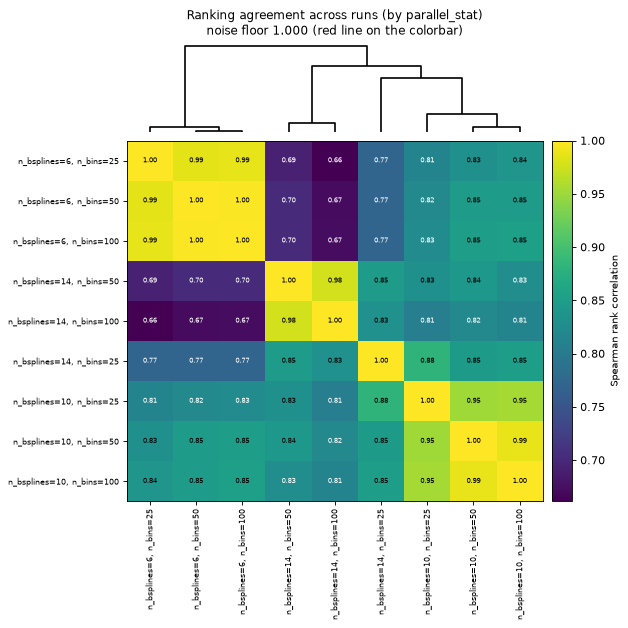

In [5]:
dvg.pl.plot_stability(stability, kind="heatmap", metric="spearman");

The same comparison against the baseline, with one setting changed at a time, shows which setting moves the ranking. The dashed line is the noise floor, the agreement of the baseline with itself, which is 1 for exact fits.

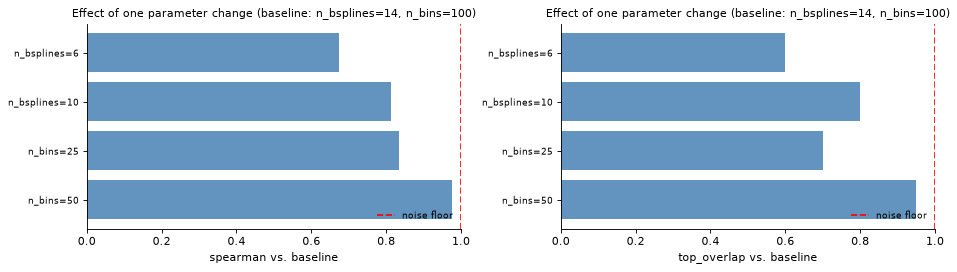

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
dvg.pl.plot_stability(stability, kind="sensitivity", metric="spearman", ax=axes[0])
dvg.pl.plot_stability(stability, kind="sensitivity", metric="top_overlap", ax=axes[1])
fig.tight_layout();

In [7]:
MIN_SPEARMAN, MIN_TOP_OVERLAP = 0.95, 0.8

runs = stability.configs[["n_bsplines", "n_bins"]].astype(int)
runs["spearman"] = stability.similarity.loc[stability.baseline, runs.index]
runs["top_overlap"] = stability.top_overlap.loc[stability.baseline, runs.index]
runs["close to the richest"] = (runs["spearman"] >= MIN_SPEARMAN) & (runs["top_overlap"] >= MIN_TOP_OVERLAP)

best = runs[runs["close to the richest"]].sort_values(["n_bsplines", "n_bins"]).iloc[0]
N_BSPLINES, N_BINS = int(best["n_bsplines"]), int(best["n_bins"])
print(f"Kept: n_bsplines = {N_BSPLINES}, n_bins = {N_BINS}")
runs.sort_values(["n_bsplines", "n_bins"]).round(3)

Kept: n_bsplines = 14, n_bins = 50


,n_bsplines,n_bins,spearman,top_overlap,close to the richest
"n_bsplines=6, n_bins=25",6,25,0.661,0.65,False
"n_bsplines=6, n_bins=50",6,50,0.671,0.60,False
"n_bsplines=6, n_bins=100",6,100,0.673,0.60,False
"n_bsplines=10, n_bins=25",10,25,0.806,0.75,False
"n_bsplines=10, n_bins=50",10,50,0.821,0.85,False
"n_bsplines=10, n_bins=100",10,100,0.814,0.80,False
"n_bsplines=14, n_bins=25",14,25,0.833,0.70,False
"n_bsplines=14, n_bins=50",14,50,0.977,0.95,True
"n_bsplines=14, n_bins=100",14,100,1.000,1.00,True


`n_bsplines = 14` with `n_bins = 50` is the smallest setting close to the richest. The default `n_bsplines = 10` keeps 85% of the top 20 genes but reorders the others (Spearman 0.82), so with the defaults, rely on the top of the list.

## 2. The model with these settings

The fit uses the settings kept above, the organoids as replicates and `tau = 0`.

In [8]:
dvg.pp.bin_obs(
    adata, anchor="True", condition="condition", layer=LAYER, n_bsplines=N_BSPLINES, n_bins=N_BINS,
    window_radius=None, sample="organoid",
)  # fmt: skip
dvg.tl.fit_model(adata, dvg.tl.setup_model(adata), n_workers=N_WORKERS, test="parallel", tau=0)
stats = adata.varm["dsvg_stats"].copy()

### Did the integration work?

`exact_edge_mass` is the share of each gene's posterior that sits at the edge of the integration grid. Values near 0 mean the grid covers the posterior.

In [9]:
print(
    f"{(stats['exact_edge_mass'] < 0.05).sum()} of {len(stats)} genes have less than 5% of their posterior at the grid edge"
)

88 of 88 genes have less than 5% of their posterior at the grid edge


### Ranked genes

In [10]:
ranked = stats.sort_values(["parallel_pval", "parallel_stat"], ascending=[True, False])
FLAGGED = list(ranked.index[ranked["parallel_pval_adj"] < 0.05])
ranked[["shape_diff", "slope_diff", "parallel_pval", "parallel_pval_adj"]].head(10)

,shape_diff,slope_diff,parallel_pval,parallel_pval_adj
HHIP,1.436405,0.961389,0.000005,0.000473
GLI1,1.241363,1.035673,0.000026,0.001162
PAX7,1.258271,-0.944734,0.000055,0.001551
PTCH1,1.130237,0.267083,0.000070,0.001551
FOXA2,0.345939,0.206742,0.000178,0.003137
NEUROG2,1.039439,0.552030,0.000515,0.007553
DBX2,1.014961,0.617517,0.002484,0.031226
PROM1,0.899005,0.199527,0.004205,0.046260
JUN,1.337970,-0.935711,0.005203,0.050870
TBP,0.443536,-0.378907,0.010216,0.089900


With these settings 8 genes pass BH < 0.05. Compared with the replicates guide, which uses the default settings, TBP drops out and PTCH1, DBX2 and PROM1 come in; FOXA2, HHIP, GLI1, PAX7 and NEUROG2 pass with both.

### Volcano and p-value histogram

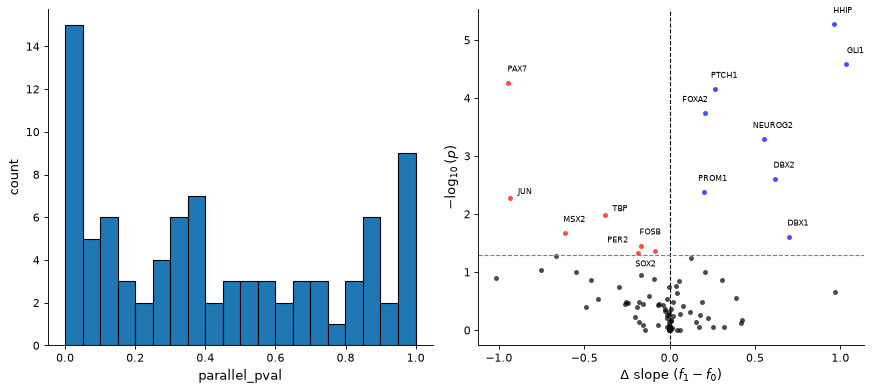

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
dvg.pl.plot_pvalue_histogram(stats, ax=axes[0])
dvg.pl.plot_volcano(stats, ax=axes[1], n_label=15)
fig.tight_layout();

Most p-values spread over the whole range, with a peak near 0 from the genes that change. The genes at p near 1 have nearly parallel curves.

## 3. Clustering

`tl.cluster_curves` runs k-means on the spline coefficients, so genes group by the shape of their curves. It answers two questions:

* `by="average"` uses the mean of the two condition curves: which patterns along the distance exist in the data?
* `by="interaction"` uses the difference between the conditions: in which ways do the conditions differ?

The silhouette (higher is better) helps to choose the number of clusters `k`. It tends to favour small `k`, so use it as a guide.

In [12]:
silhouettes = {}
for by in ("average", "interaction"):
    for k in range(2, 9):
        dvg.tl.cluster_curves(adata, by=by, n_clusters=k, key_added="scan")
        silhouettes[by, k] = adata.uns["scan"]["silhouette"]
del adata.var["scan"], adata.uns["scan"]
pd.Series(silhouettes).unstack(0).round(3).rename_axis("k")

,average,interaction
k,,
2,0.439,0.308
3,0.456,0.451
4,0.389,0.294
5,0.398,0.302
6,0.410,0.314
7,0.385,0.313
8,0.389,0.313


`k = 3` has the highest silhouette for both. The guide uses 5 clusters to show more detail, so the smaller clusters are less distinct.

In [13]:
N_CLUSTERS = 5


def cluster_table(key):
    """One row per cluster: its size, how many of its genes the test flags, and the genes."""
    labels = adata.var[key].dropna()
    return pd.DataFrame(
        {
            cluster: {
                "n": len(genes),
                "p < 0.05": int((stats.loc[genes, "parallel_pval"] < 0.05).sum()),
                "BH < 0.05": int((stats.loc[genes, "parallel_pval_adj"] < 0.05).sum()),
                "median shape_diff": round(float(stats.loc[genes, "shape_diff"].median()), 2),
                "genes": ", ".join(genes),
            }
            for cluster, genes in ((c, list(labels.index[labels == c])) for c in labels.cat.categories)
        }
    ).T

### Patterns along the distance

Each gene is centred, so only the shape of its mean curve counts, not its level.

,n,p < 0.05,BH < 0.05,median shape_diff,genes
0,49,2,0,0.08,"AIF1, ALDH1L1, AQP4, ARC, ARG1, BCL11B, BMP4, ..."
1,23,10,6,0.44,"AC129492.1, AGO2, Circ.CDR1, CUL3, DBX1, DBX2,..."
2,7,2,1,0.6,"GLI2, GLI3, MAP2, PAX7, PTPRZ1, SOX2, ZNF609"
3,5,0,0,0.67,"Circ.RMST, IRX3, PAX6, STMN2, TUBB3"
4,4,1,1,0.31,"FOXA1, FOXA2, NKX6.1, SHH"


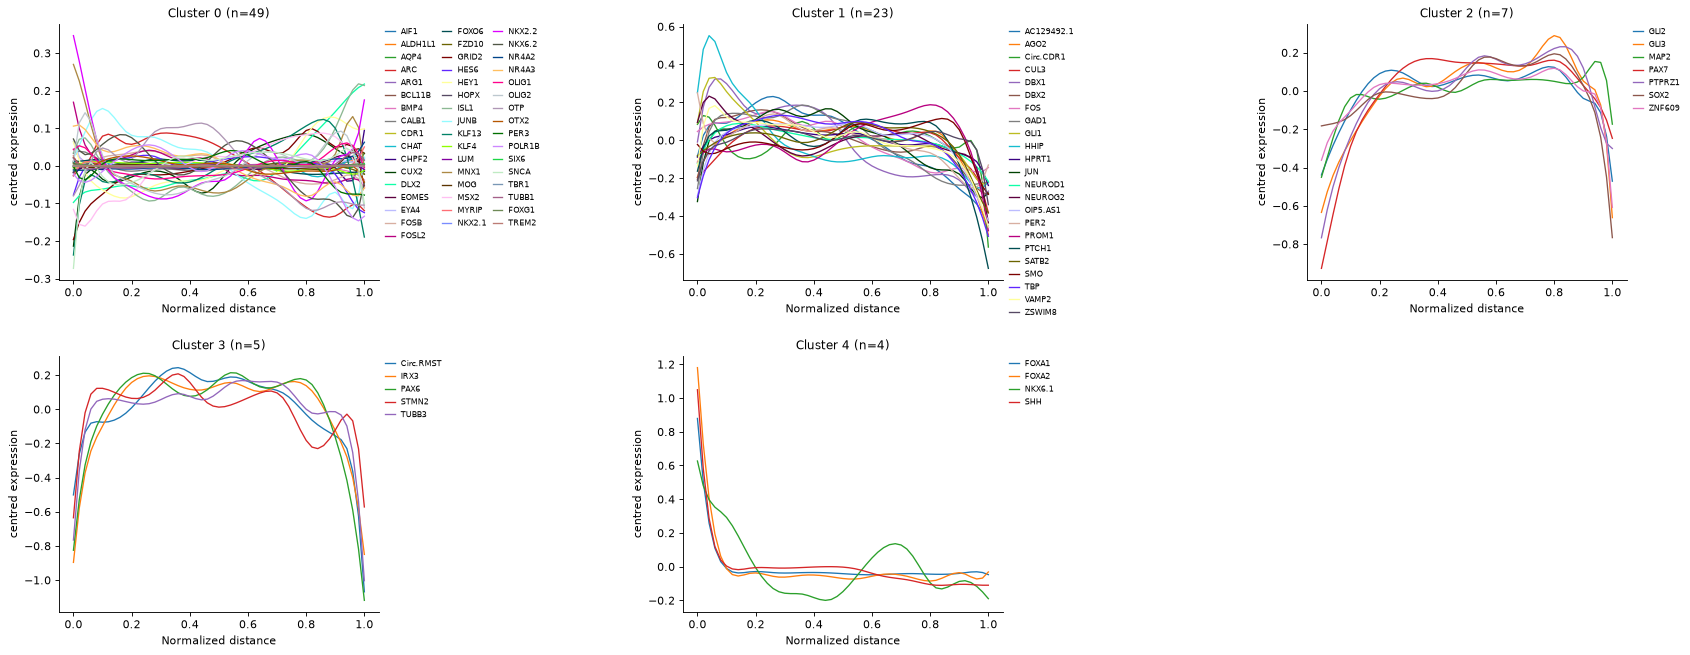

In [14]:
dvg.tl.cluster_curves(adata, by="average", n_clusters=N_CLUSTERS)
display(cluster_table("dsvg_cluster_average"))
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_average");

Cluster 0 holds about half of the genes, with no clear pattern along the distance. The ventral genes FOXA1, FOXA2, NKX6.1 and SHH form their own cluster (4), and the progenitor and dorsal genes GLI2, GLI3, PAX7 and SOX2 another one (2).

### How the conditions differ

The plot shows the difference curves, SHH minus Ctrl. Genes without a difference collect in a flat cluster. The clustering uses the same coefficients as the test, so it describes the flagged genes and doesn't confirm them.

,n,p < 0.05,BH < 0.05,median shape_diff,genes
0,50,2,0,0.08,"AIF1, ALDH1L1, AQP4, ARC, ARG1, BCL11B, BMP4, ..."
1,23,4,2,0.44,"AGO2, CUL3, DBX2, GAD1, GLI2, GLI3, HES6, KLF1..."
2,7,6,5,1.19,"DBX1, FOXA2, GLI1, HHIP, NEUROG2, NKX6.1, PTCH1"
3,6,2,0,0.8,"AC129492.1, FOS, IRX3, JUN, JUNB, MSX2"
4,2,1,1,1.11,"Circ.RMST, PAX7"


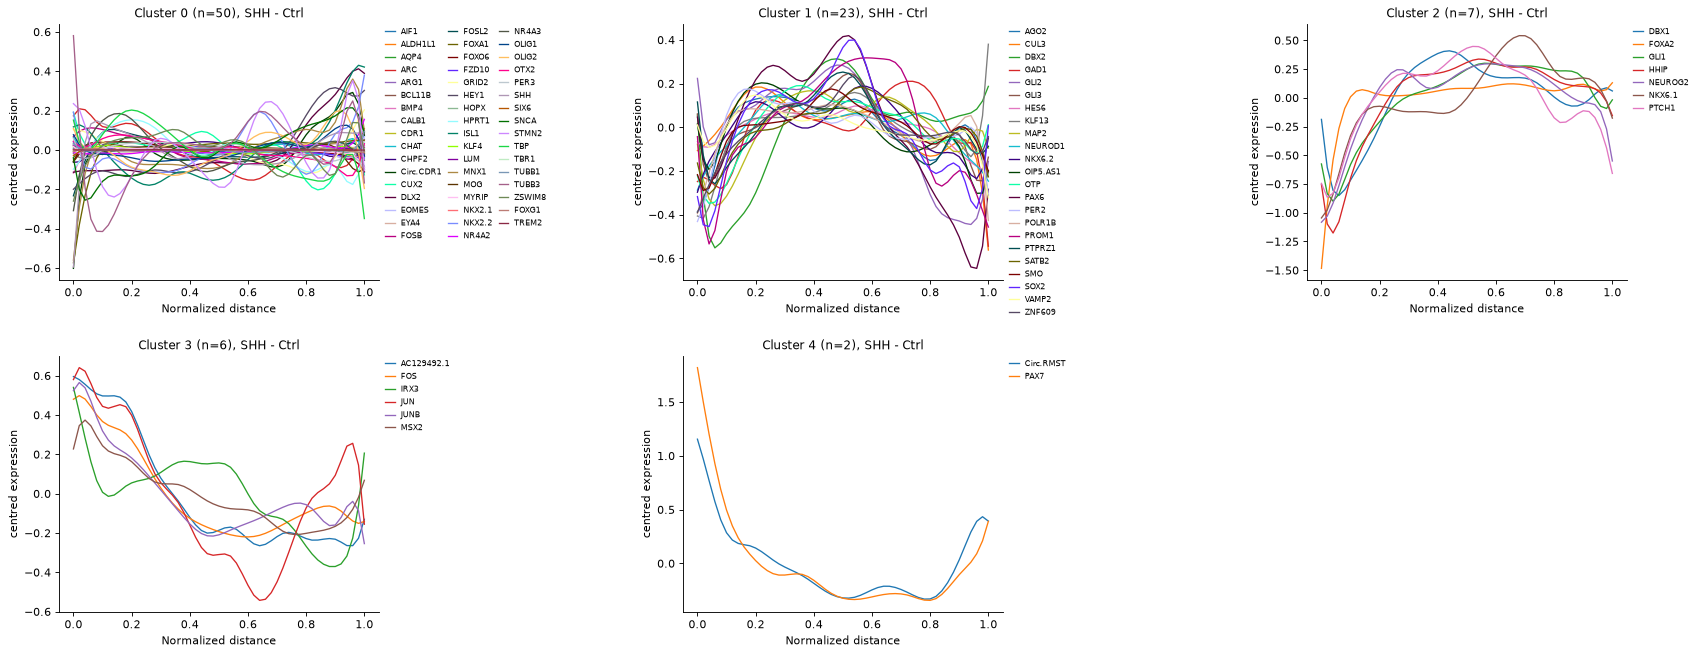

In [15]:
dvg.tl.cluster_curves(adata, by="interaction", n_clusters=N_CLUSTERS)
display(cluster_table("dsvg_cluster_interaction"))
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_interaction");

Cluster 2 holds the SHH targets and ventral genes (GLI1, PTCH1, HHIP, FOXA2, NKX6.1), 5 of them flagged, and cluster 4 the dorsal gene PAX7. Cluster 3 mixes the dorsal genes IRX3 and MSX2 with the immediate-early genes FOS, JUN and JUNB. Immediate-early genes often respond to tissue handling, so treat them like the housekeeping gene TBP in the replicates guide.

The same clusters split by condition, Ctrl left and SHH right, for the clusters that hold flagged genes:

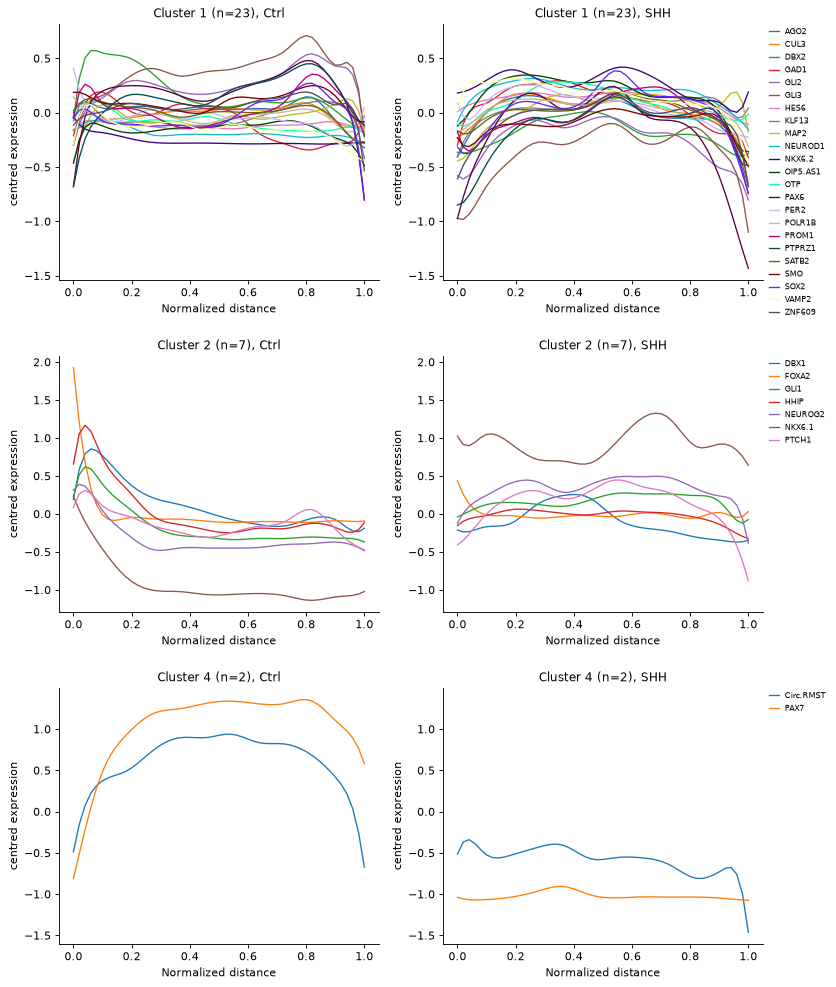

In [16]:
labels = adata.var["dsvg_cluster_interaction"]
with_flagged = sorted(set(labels[FLAGGED])) or None
dvg.pl.plot_cluster_curves(adata, "dsvg_cluster_interaction", curves="conditions", clusters=with_flagged);

In cluster 2, the SHH targets and ventral genes peak near the anchor in the controls and are nearly flat in the SHH organoids, where NKX6.1 is high everywhere. In cluster 4, PAX7 and Circ.RMST rise away from the anchor in the controls and stay low in the SHH organoids.